In [7]:
# imports

import pandas as pd
from pathlib import Path
import os   
import random
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
import pandas as pd
from pathlib import Path

# Cell 0: read Excel into a DataFrame

file_path = Path("data.xlsx")
if not file_path.exists():
    raise FileNotFoundError(f"{file_path} not found (cwd: {Path.cwd()})")

# Read the first sheet. Use sheet_name=None to read all sheets into a dict.
df = pd.read_excel(file_path, engine="openpyxl")
print(f"Loaded DataFrame with shape: {df.shape}")
df.head()

Loaded DataFrame with shape: (34567, 227)


,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.6,3.5,...,83.45,3.0,81.40,1.0,97.4,1.0,97.4,3.0,95.0,1.0
1,Alabama,AL,Autauga County,1001,2009,5.93,5.72,6.11,4.8,4.6,...,87.39,3.0,85.68,1.0,102.0,1.0,102.0,3.0,100.0,1.0
2,Alabama,AL,Autauga County,1001,2010,6.21,5.57,6.78,5.1,4.6,...,91.33,3.0,89.96,1.0,106.6,1.0,106.6,3.0,105.0,1.0
3,Alabama,AL,Autauga County,1001,2011,7.55,8.13,7.03,6.2,6.3,...,95.28,3.0,94.25,1.0,111.2,1.0,111.2,3.0,110.0,1.0
4,Alabama,AL,Autauga County,1001,2012,8.60,8.88,8.29,6.7,6.4,...,99.22,3.0,98.53,1.0,115.8,1.0,115.8,3.0,115.0,1.0


In [2]:
# save the existing DataFrame `df` (loaded from file_path) to a CSV next to the original Excel file
csv_path = file_path.with_suffix(".csv")
df.to_csv(csv_path, index=False, encoding="utf-8")
print(f"Saved CSV: {csv_path}")

Saved CSV: data.csv


In [3]:
# sample 100 random rows (or fewer if df has <100 rows) and save with headers next to the original Excel file
sample_count = min(len(df), 100)
sample_df = df.sample(n=sample_count, random_state=42)
sample_path = file_path.with_name("sample.csv")
sample_df.to_csv(sample_path, index=False, encoding="utf-8")
print(f"Saved sample ({sample_df.shape}) to: {sample_path}")

Saved sample ((100, 227)) to: sample.csv


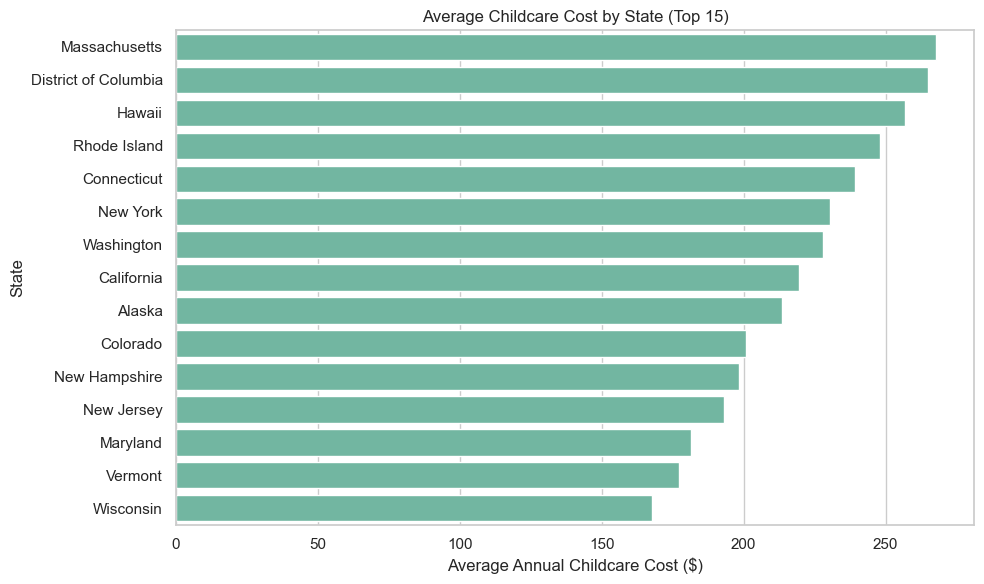

/var/folders/11/dxk146610qn60jn0f0xly1800000gn/T/ipykernel_57188/2142340252.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cost_burden.values, y=cost_burden.index, palette="flare")


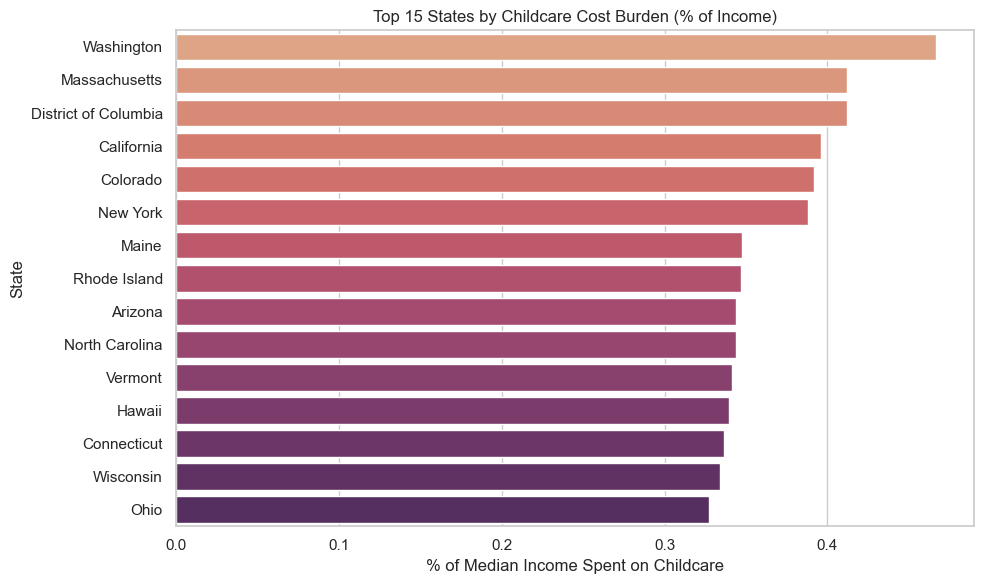

In [10]:
# ===========================================
# Childcare Costs, Poverty & Employment Visualization Dashboard
# ===========================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Load and prepare data ---

# Basic cleanup
df = df.dropna(subset=["MHI", "ME", "PR_P", "FLFPR_20to64", "MCInfant", "MCToddler", "MCPreschool"])

# Calculate average childcare cost across age groups
df["AvgChildcareCost"] = df[["MCInfant", "MCToddler", "MCPreschool"]].mean(axis=1)

# Cost as a percentage of median income
df["CostPctIncome"] = (df["AvgChildcareCost"] / df["MHI"]) * 100

# Set consistent visual style
sns.set(style="whitegrid", palette="Set2")

# ===========================================
# 1. Average Childcare Cost by State
# ===========================================
plt.figure(figsize=(10,6))
avg_cost = df.groupby("State_Name")["AvgChildcareCost"].mean().sort_values(ascending=False).head(15)
sns.barplot(x=avg_cost.values, y=avg_cost.index)
plt.title("Average Childcare Cost by State (Top 15)")
plt.xlabel("Average Annual Childcare Cost ($)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

# ===========================================
# 3. Childcare Cost as % of Income by State
# ===========================================
cost_burden = df.groupby("State_Name")["CostPctIncome"].mean().sort_values(ascending=False).head(15)
plt.figure(figsize=(10,6))
sns.barplot(x=cost_burden.values, y=cost_burden.index, palette="flare")
plt.title("Top 15 States by Childcare Cost Burden (% of Income)")
plt.xlabel("% of Median Income Spent on Childcare")
plt.ylabel("State")
plt.tight_layout()
plt.show()


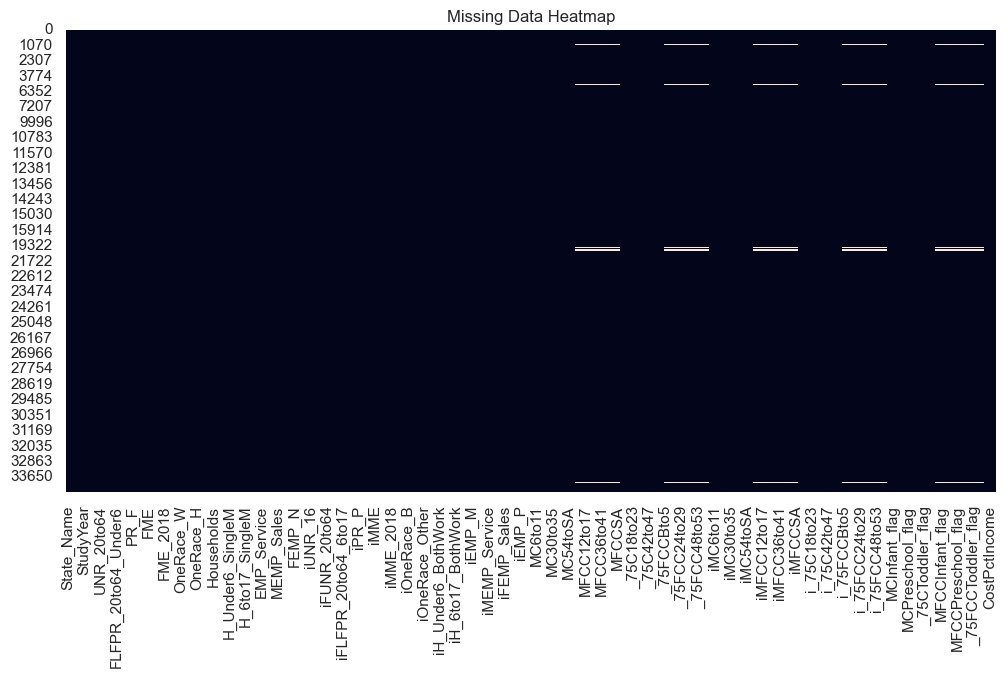

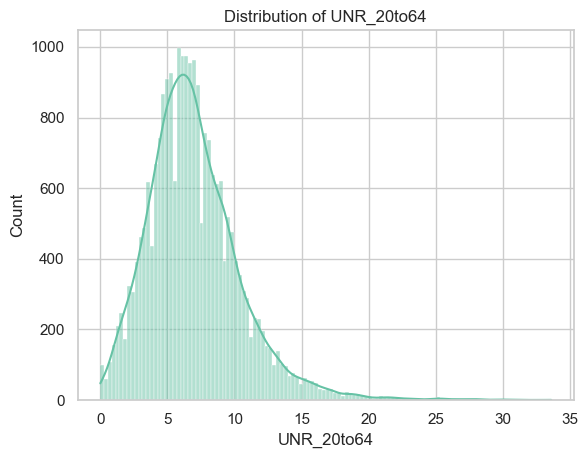

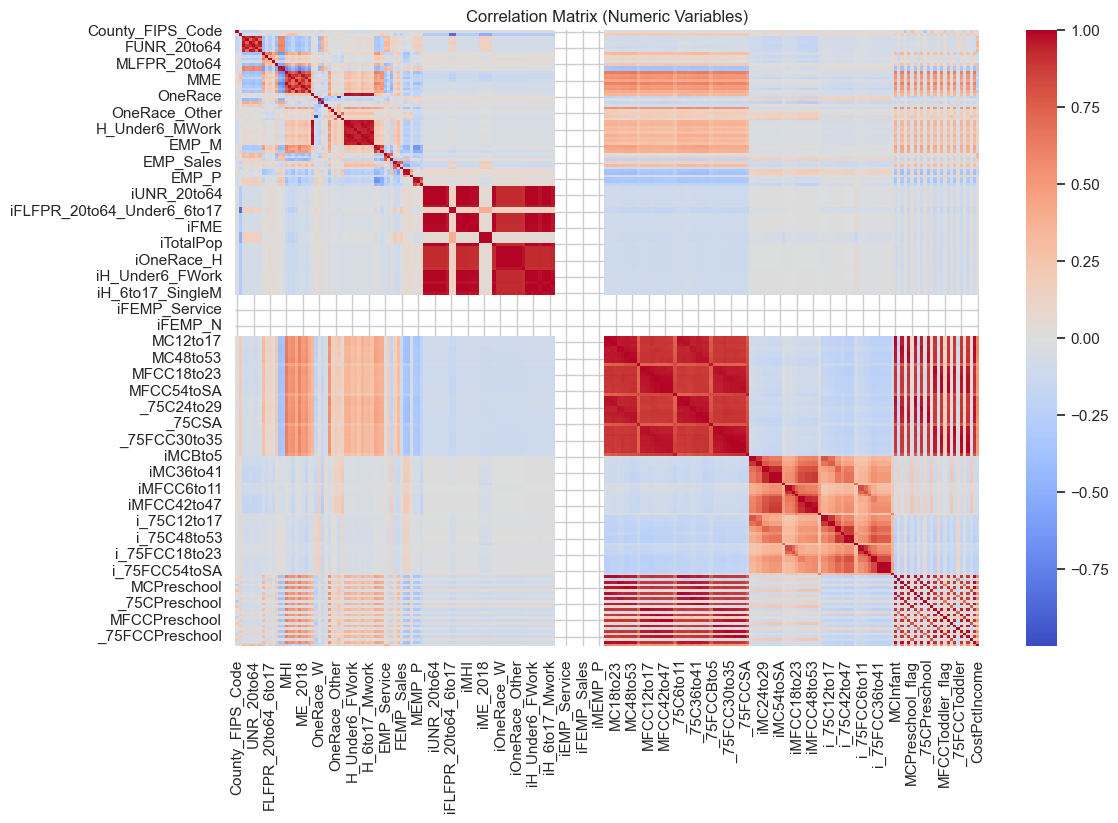

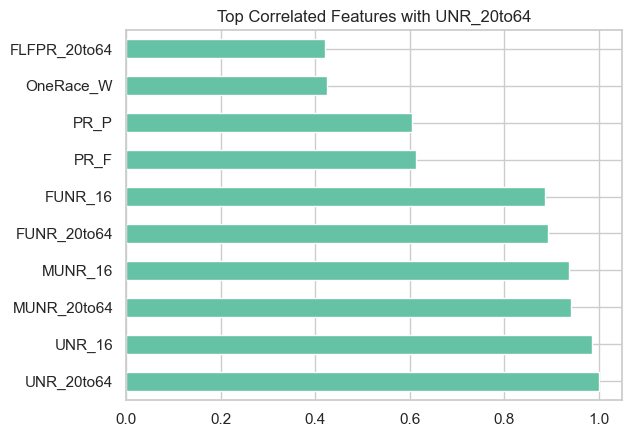

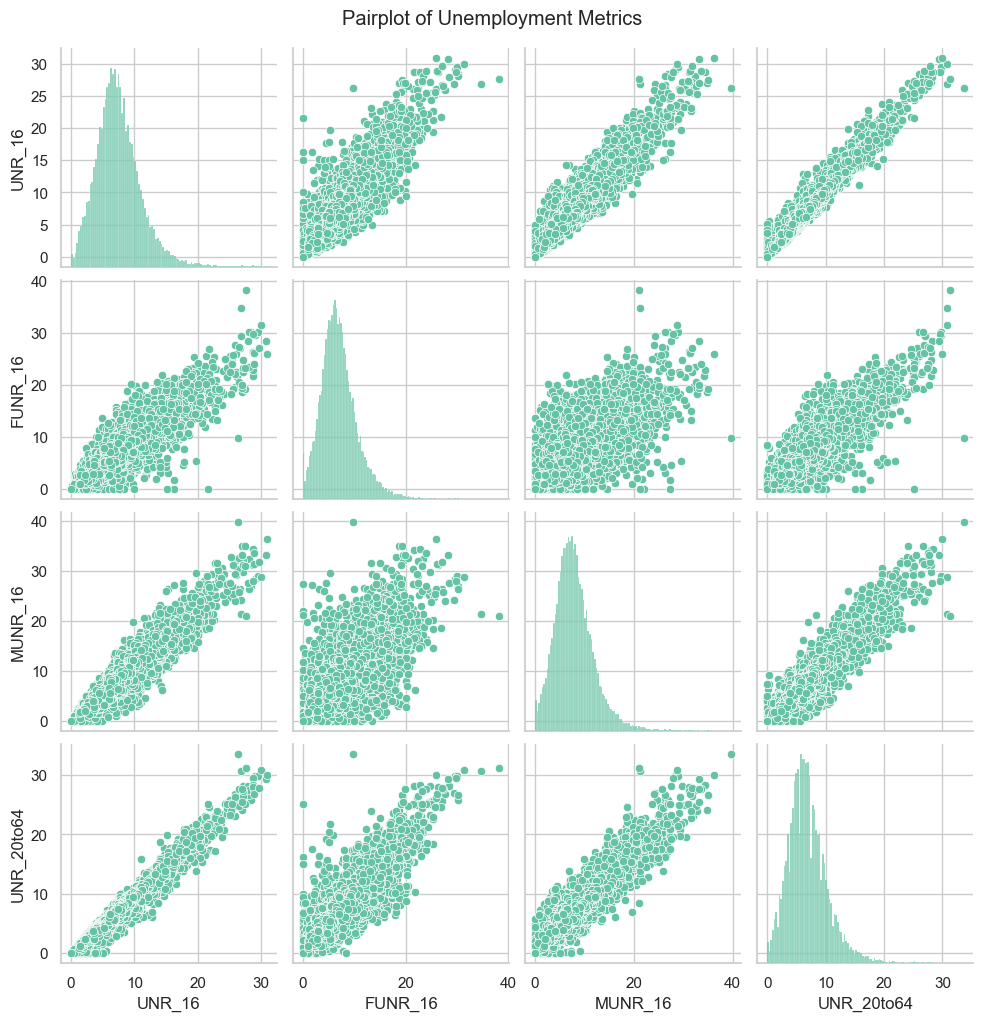

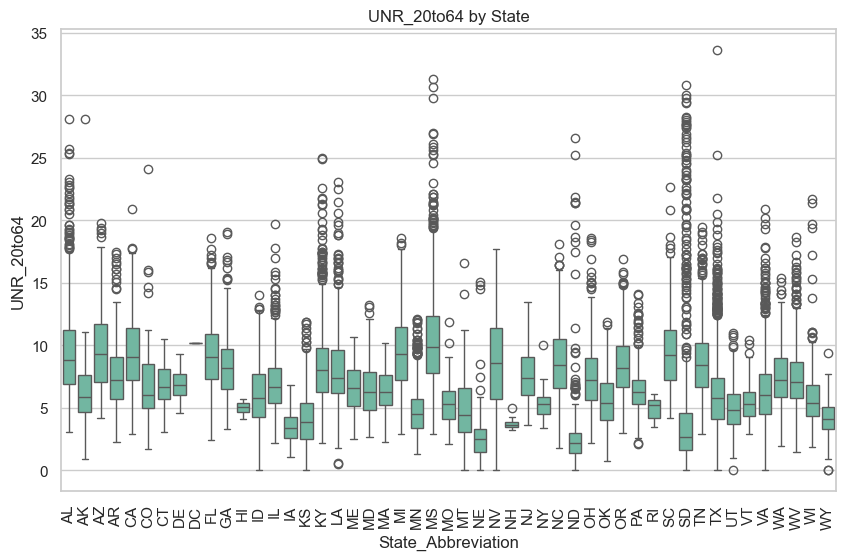

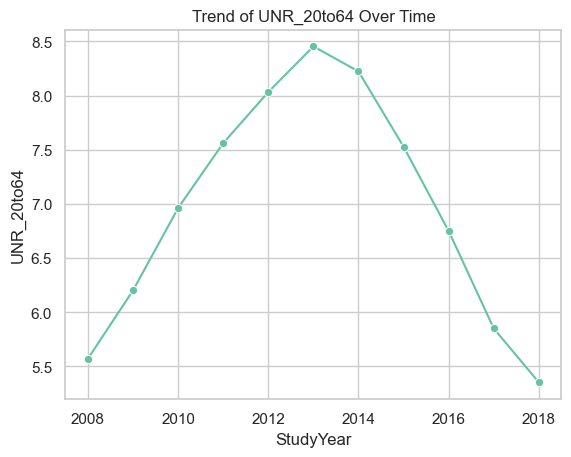

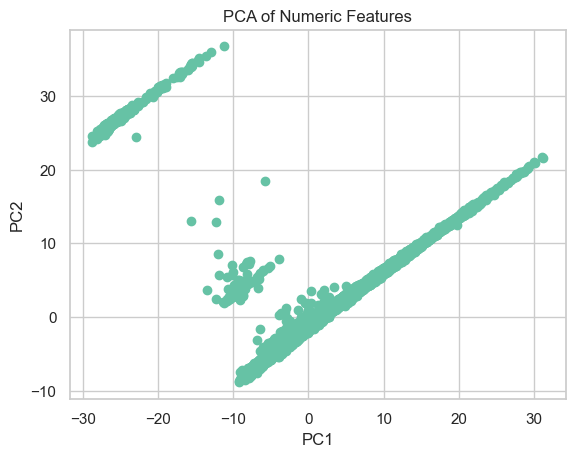

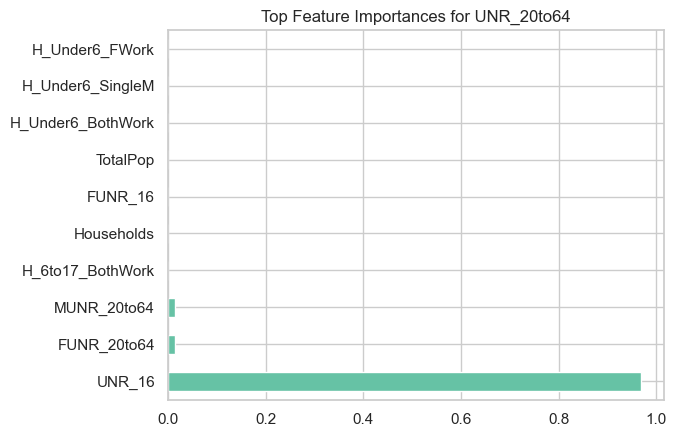

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor



# 1️⃣ Missing Values Heatmap
plt.figure(figsize=(12,6))
sns.heatmap(df.isna(), cbar=False)
plt.title("Missing Data Heatmap")
plt.show()

# 2️⃣ Distribution of a numeric column (e.g., UNR_20to64)
sns.histplot(df['UNR_20to64'], kde=True)
plt.title("Distribution of UNR_20to64")
plt.show()

# 3️⃣ Correlation Heatmap
corr = df.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Matrix (Numeric Variables)")
plt.show()

# 4️⃣ Top correlated features with a target variable
target = "UNR_20to64"
top_corr = corr[target].abs().sort_values(ascending=False).head(10)
top_corr.plot(kind='barh', title=f"Top Correlated Features with {target}")
plt.show()

# 5️⃣ Pairplot of selected features
features = ['UNR_16', 'FUNR_16', 'MUNR_16', 'UNR_20to64']
sns.pairplot(df[features])
plt.suptitle("Pairplot of Unemployment Metrics", y=1.02)
plt.show()

# 6️⃣ Boxplot by State
plt.figure(figsize=(10,6))
sns.boxplot(x="State_Abbreviation", y="UNR_20to64", data=df)
plt.xticks(rotation=90)
plt.title("UNR_20to64 by State")
plt.show()

# 7️⃣ Choropleth Map (by State)
map_df = df.groupby("State_Name", as_index=False)["UNR_20to64"].mean()
fig = px.choropleth(map_df, locations="State_Name", locationmode="USA-states",
                    color="UNR_20to64", scope="usa",
                    title="Average UNR_20to64 by State")
fig.show()

# 8️⃣ Trend Over Time
df_year = df.groupby("StudyYear", as_index=False)["UNR_20to64"].mean()
sns.lineplot(data=df_year, x="StudyYear", y="UNR_20to64", marker="o")
plt.title("Trend of UNR_20to64 Over Time")
plt.show()

# 9️⃣ PCA Scatter Plot
numeric_df = df.select_dtypes(include=[np.number]).dropna(axis=1)
X_scaled = StandardScaler().fit_transform(numeric_df)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)
plt.scatter(pca_result[:,0], pca_result[:,1])
plt.title("PCA of Numeric Features")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# 🔟 Feature Importance via Random Forest
y = df[target]
X = df.select_dtypes(include=[np.number]).drop(columns=[target]).fillna(0)
rf = RandomForestRegressor(random_state=42)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)[:10]
importances.plot(kind='barh', title=f"Top Feature Importances for {target}")
plt.show()


In [ ]:
cols_to_keep = ['State_Name','County_Name','StudyYear']

short_name_long_name = {
    'UNR_16':'Unemployment 16 & Older',
    'FUNR_16':'Female Unemployment 16 & Older',
    'MUNR_16':'Male Unemployment 16 & Older',
    
    'UNR_20to64':'Unemployment 20-64 Year Olds',
    'PR_F':'Poverty Rate Families',
    'MHI_2018':'Median Household Income (2018 Dollars)',

}